# 48 · PPO from scratch: MuJoCo cart-pole (discrete), then Panda reaching (continuous)

In [1]:
import time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from vlacourse.rl_envs import CartPoleEnv, PandaReachEnv
from vlacourse import show_video

torch.set_num_threads(4)

class ActorCritic(nn.Module):
    def __init__(self, obs_dim, act_dim, discrete, hidden=64):
        super().__init__()
        self.discrete = discrete
        self.pi = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, act_dim))
        self.v = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, 1))
        self.log_std = nn.Parameter(-0.5 * torch.ones(act_dim)) if not discrete else None

    def dist(self, obs):
        out = self.pi(obs)
        if self.discrete:
            return torch.distributions.Categorical(logits=out)
        return torch.distributions.Normal(out, self.log_std.exp())

    def logp(self, d, a):
        return d.log_prob(a) if self.discrete else d.log_prob(a).sum(-1)

def collect(env, ac, n_steps, obs, ep_stats):
    O, A, LP, R, D, V = [], [], [], [], [], []
    for _ in range(n_steps):
        o = torch.tensor(obs)
        with torch.no_grad():
            d = ac.dist(o); a = d.sample(); lp = ac.logp(d, a); v = ac.v(o)[0]
        act = a.item() if ac.discrete else a.numpy()
        obs2, r, te, tr, info = env.step(act)
        O.append(o); A.append(a); LP.append(lp); R.append(r); D.append(te); V.append(v)
        ep_stats["ret"] += r; ep_stats["len"] += 1
        if te or tr:
            ep_stats["done"].append((ep_stats["ret"], ep_stats["len"], info.get("success", False)))
            ep_stats["ret"], ep_stats["len"] = 0.0, 0
            obs2, _ = env.reset()
            if tr and not te:
                D[-1] = "trunc"
                with torch.no_grad():
                    R[-1] = r + 0.99 * ac.v(torch.tensor(obs))[0].item()
        obs = obs2
    with torch.no_grad():
        last_v = ac.v(torch.tensor(obs))[0]
    return dict(O=torch.stack(O), A=torch.stack(A), LP=torch.stack(LP), R=torch.tensor(R, dtype=torch.float32),
                D=torch.tensor([d is not False for d in D], dtype=torch.float32), V=torch.stack(V), last_v=last_v), obs

def gae(R, V, D, last_v, gamma=0.99, lam=0.95):
    adv, g = torch.zeros_like(R), 0.0
    for t in reversed(range(len(R))):
        nv = last_v if t == len(R) - 1 else V[t + 1]
        delta = R[t] + gamma * nv * (1 - D[t]) - V[t]
        g = delta + gamma * lam * (1 - D[t]) * g
        adv[t] = g
    return adv, adv + V

def ppo(env, discrete, total_steps, n_steps=2048, epochs=10, mb=64, clip=0.2, lr=3e-4, ent=0.0, seed=0, log_every=1):
    torch.manual_seed(seed)
    obs_dim = env.observation_space.shape[0]
    act_dim = env.action_space.n if discrete else env.action_space.shape[0]
    ac = ActorCritic(obs_dim, act_dim, discrete)
    opt = torch.optim.Adam(ac.parameters(), lr=lr)
    obs, _ = env.reset(seed=seed)
    stats, log, steps = {"ret": 0.0, "len": 0, "done": []}, [], 0
    while steps < total_steps:
        buf, obs = collect(env, ac, n_steps, obs, stats); steps += n_steps
        adv, ret = gae(buf["R"], buf["V"], buf["D"], buf["last_v"])
        adv = (adv - adv.mean()) / (adv.std() + 1e-8)
        kls, clipfracs = [], []
        for _ in range(epochs):
            for idx in torch.randperm(n_steps).split(mb):
                d = ac.dist(buf["O"][idx]); lp = ac.logp(d, buf["A"][idx])
                ratio = (lp - buf["LP"][idx]).exp()
                pg = -torch.min(ratio * adv[idx], ratio.clamp(1 - clip, 1 + clip) * adv[idx]).mean()
                vl = ((ac.v(buf["O"][idx]).squeeze(-1) - ret[idx]) ** 2).mean()
                loss = pg + 0.5 * vl - ent * d.entropy().mean()
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(ac.parameters(), 0.5); opt.step()
                with torch.no_grad():
                    kls.append(((ratio - 1) - (lp - buf["LP"][idx])).mean().item())
                    clipfracs.append(((ratio - 1).abs() > clip).float().mean().item())
        recent = stats["done"][-20:]
        log.append(dict(steps=steps, ret=np.mean([r for r, _, _ in recent]) if recent else np.nan,
                        success=np.mean([s for _, _, s in recent]) if recent else np.nan, kl=np.mean(kls), clipfrac=np.mean(clipfracs)))
    return ac, log

def plot_log(log, title, key="ret"):
    s = [l["steps"] for l in log]
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
    ax[0].plot(s, [l[key] for l in log]); ax[0].set_xlabel("env steps"); ax[0].set_ylabel(key); ax[0].set_title(title)
    ax[1].plot(s, [l["kl"] for l in log], label="approx KL(old‖new)"); ax[1].plot(s, [l["clipfrac"] for l in log], label="clip fraction")
    ax[1].set_xlabel("env steps"); ax[1].legend(); plt.tight_layout(); plt.show()

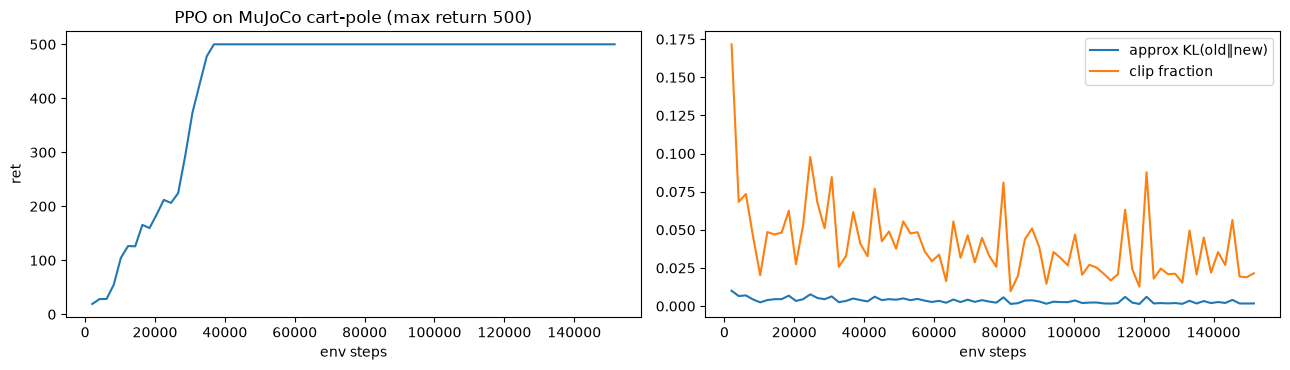

steps to 475 average return: 34816 | wall clock 244s


In [2]:
t0 = time.time()
ac_cp, log_cp = ppo(CartPoleEnv(), discrete=True, total_steps=150_000)
plot_log(log_cp, "PPO on MuJoCo cart-pole (max return 500)")
hit = next((l["steps"] for l in log_cp if l["ret"] >= 475), None)
print(f"steps to 475 average return: {hit} | wall clock {time.time() - t0:.0f}s")

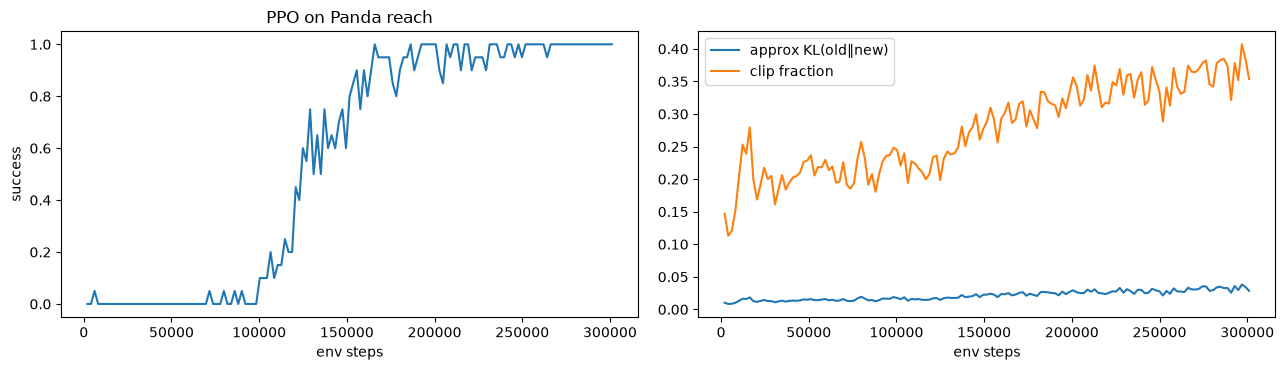

final success rate (last 20 episodes): 1.00 | wall clock 506s


In [3]:
t0 = time.time()
reach = PandaReachEnv()
ac_reach, log_reach = ppo(reach, discrete=False, total_steps=300_000, lr=3e-4)
plot_log(log_reach, "PPO on Panda reach", key="success")
print(f"final success rate (last 20 episodes): {log_reach[-1]['success']:.2f} | wall clock {time.time() - t0:.0f}s")

deterministic policy (mean action): 20/20 targets reached


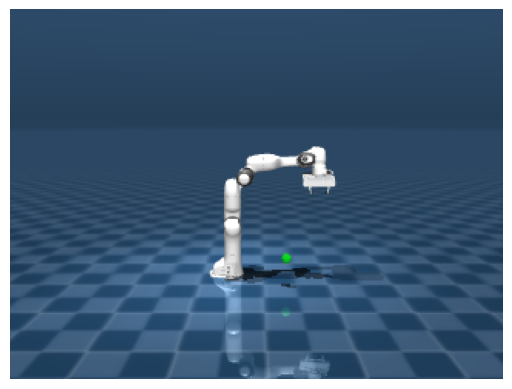

In [4]:
env = PandaReachEnv(); frames, wins = [], 0
for ep in range(20):
    obs, _ = env.reset(seed=1000 + ep); done = False
    while not done:
        with torch.no_grad():
            a = ac_reach.pi(torch.tensor(obs)).numpy()
        obs, r, te, tr, info = env.step(a); done = te or tr
        if ep < 3:
            cam = None
            frames.append(env.render(camera=None))
    wins += info["success"]
print(f"deterministic policy (mean action): {wins}/20 targets reached")
show_video(frames, fps=20, title="PPO Panda reach")
plt.imshow(frames[len(frames) // 3]); plt.axis("off"); plt.show()